# 03 — Corrélations

**Entrée** : `data/processed/co2_clean.csv`  
Analyse des corrélations entre les émissions de CO₂ et les autres variables (PIB, population, usage des sols, température).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
df = pd.read_csv("../data/processed/co2_clean.csv")

df.head()

,country,iso_code,year,population,gdp,co2,co2_per_capita,cumulative_co2,co2_growth_prct,coal_co2,oil_co2,gas_co2,land_use_change_co2,methane,nitrous_oxide,temperature_change_from_co2,temperature_change_from_ghg
0,Afghanistan,AFG,1949,7356890.0,NaN,0.014656,0.001992,0.014656,NaN,0.014656,0.000000,0.0,6.102172,7.729318,2.162319,0.000307,0.000528
1,Afghanistan,AFG,1950,7776180.0,9.421400e+09,0.084272,0.010837,0.098928,475.000000,0.021068,0.063204,0.0,7.084747,7.879157,2.230887,0.000311,0.000538
2,Afghanistan,AFG,1951,7879343.0,9.692280e+09,0.091600,0.011625,0.190528,8.695650,0.025648,0.065952,0.0,8.000418,7.972563,2.292099,0.000316,0.000548
3,Afghanistan,AFG,1952,7987784.0,1.001732e+10,0.091600,0.011468,0.282128,0.000000,0.031708,0.059892,0.0,8.913743,8.072992,2.365288,0.000321,0.000560
4,Afghanistan,AFG,1953,8096703.0,1.063052e+10,0.106256,0.013123,0.388384,15.999996,0.037949,0.068307,0.0,9.963808,8.185520,2.446641,0.000327,0.000571


In [15]:
variables = [
    "co2",
    "gdp",
    "population",
    "land_use_change_co2",
    "temperature_change_from_ghg"
]

df[variables].describe()

,co2,gdp,population,land_use_change_co2,temperature_change_from_ghg
count,19787.000000,1.341000e+04,1.957400e+04,18310.000000,19787.000000
mean,88.942984,2.778557e+11,2.407218e+07,44.580345,0.004243
std,474.461126,1.155298e+12,9.578340e+07,155.700276,0.016430
min,0.000000,5.543200e+07,1.472000e+03,-319.417542,-0.000613
25%,0.450672,9.269612e+09,1.098104e+06,0.056957,0.000133
50%,3.967755,3.127831e+10,4.564844e+06,5.310620,0.000703
75%,30.331270,1.388641e+11,1.391266e+07,26.613996,0.002368
max,12289.037109,2.696602e+13,1.450936e+09,2998.516357,0.296246


In [16]:
df_corr_gdp = df[["co2", "gdp"]].dropna()

correlation_gdp = df_corr_gdp["co2"].corr(df_corr_gdp["gdp"])

print("Corrélation entre CO₂ et PIB :", correlation_gdp)
print("Nombre d'observations :", len(df_corr_gdp))

Corrélation entre CO₂ et PIB : 0.9250120431015539
Nombre d'observations : 13410


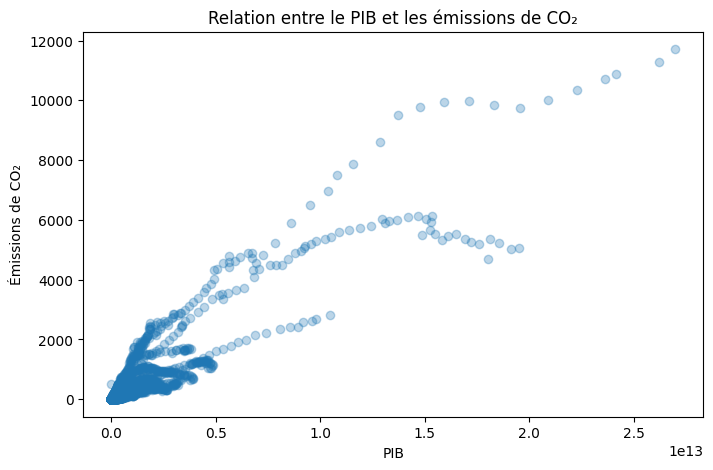

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_corr_gdp["gdp"],
    df_corr_gdp["co2"],
    alpha=0.3
)

plt.xlabel("PIB")
plt.ylabel("Émissions de CO₂")
plt.title("Relation entre le PIB et les émissions de CO₂")

plt.show()

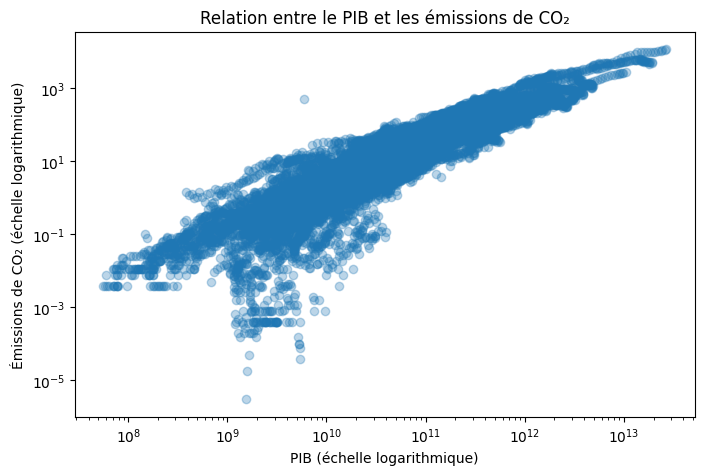

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_corr_gdp["gdp"],
    df_corr_gdp["co2"],
    alpha=0.3
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("PIB (échelle logarithmique)")
plt.ylabel("Émissions de CO₂ (échelle logarithmique)")
plt.title("Relation entre le PIB et les émissions de CO₂")

plt.show()

In [22]:
df_corr_population = df[["co2", "population"]].dropna()

correlation_population = df_corr_population["co2"].corr(
    df_corr_population["population"]
)

print("Corrélation entre CO₂ et population :", correlation_population)
print("Nombre d'observations :", len(df_corr_population))

Corrélation entre CO₂ et population : 0.6340626620103299
Nombre d'observations : 19574


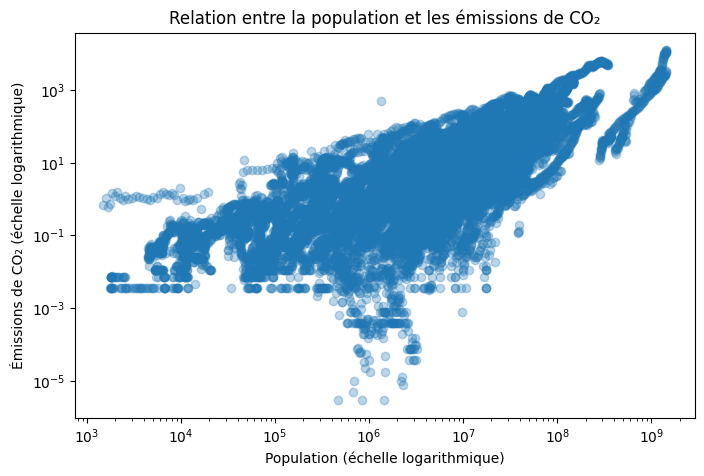

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_corr_population["population"],
    df_corr_population["co2"],
    alpha=0.3
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Population (échelle logarithmique)")
plt.ylabel("Émissions de CO₂ (échelle logarithmique)")
plt.title("Relation entre la population et les émissions de CO₂")

plt.show()

In [24]:
print(df.columns.tolist())

['country', 'iso_code', 'year', 'population', 'gdp', 'co2', 'co2_per_capita', 'cumulative_co2', 'co2_growth_prct', 'coal_co2', 'oil_co2', 'gas_co2', 'land_use_change_co2', 'methane', 'nitrous_oxide', 'temperature_change_from_co2', 'temperature_change_from_ghg']


In [25]:
df["fossil_co2"] = df[["coal_co2", "oil_co2", "gas_co2"]].sum(axis=1, min_count=1)

df[["coal_co2", "oil_co2", "gas_co2", "fossil_co2"]].head()

,coal_co2,oil_co2,gas_co2,fossil_co2
0,0.014656,0.000000,0.0,0.014656
1,0.021068,0.063204,0.0,0.084272
2,0.025648,0.065952,0.0,0.091600
3,0.031708,0.059892,0.0,0.091600
4,0.037949,0.068307,0.0,0.106256


In [26]:
df_corr_energy = df[["co2", "fossil_co2"]].dropna()

correlation_energy = df_corr_energy["co2"].corr(
    df_corr_energy["fossil_co2"]
)

print("Corrélation entre CO₂ et émissions fossiles :", correlation_energy)
print("Nombre d'observations :", len(df_corr_energy))

Corrélation entre CO₂ et émissions fossiles : 0.9994598496730276
Nombre d'observations : 19612


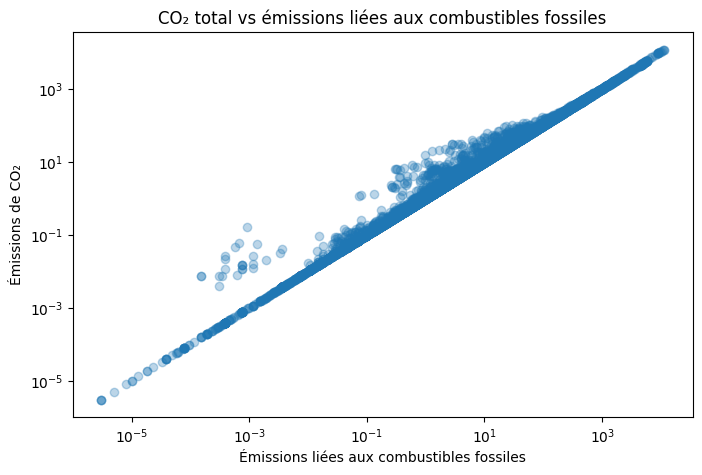

In [27]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_corr_energy["fossil_co2"],
    df_corr_energy["co2"],
    alpha=0.3
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Émissions liées aux combustibles fossiles")
plt.ylabel("Émissions de CO₂")
plt.title("CO₂ total vs émissions liées aux combustibles fossiles")

plt.show()

In [29]:
df_corr_land = df[["co2", "land_use_change_co2"]].dropna()

correlation_land = df_corr_land["co2"].corr(
    df_corr_land["land_use_change_co2"]
)

print("Corrélation entre CO₂ et changement d'utilisation des terres :", correlation_land)
print("Nombre d'observations :", len(df_corr_land))

Corrélation entre CO₂ et changement d'utilisation des terres : 0.17151305121033952
Nombre d'observations : 18310


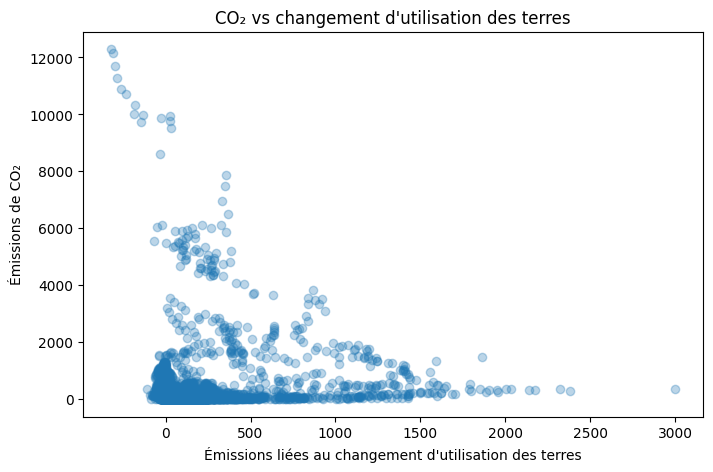

In [30]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_corr_land["land_use_change_co2"],
    df_corr_land["co2"],
    alpha=0.3
)

plt.xlabel("Émissions liées au changement d'utilisation des terres")
plt.ylabel("Émissions de CO₂")
plt.title("CO₂ vs changement d'utilisation des terres")

plt.show()

In [31]:
corr_year = df.groupby("year").apply(
    lambda x: x["co2"].corr(x["gdp"])
)

corr_year = corr_year.dropna()

print(corr_year.head())
print(corr_year.tail())

year
1900    0.918647
1901    0.926102
1902    0.921925
1903    0.927322
1904    0.926293
dtype: float64
year
2018    0.965071
2019    0.963819
2020    0.960056
2021    0.966446
2022    0.964109
dtype: float64


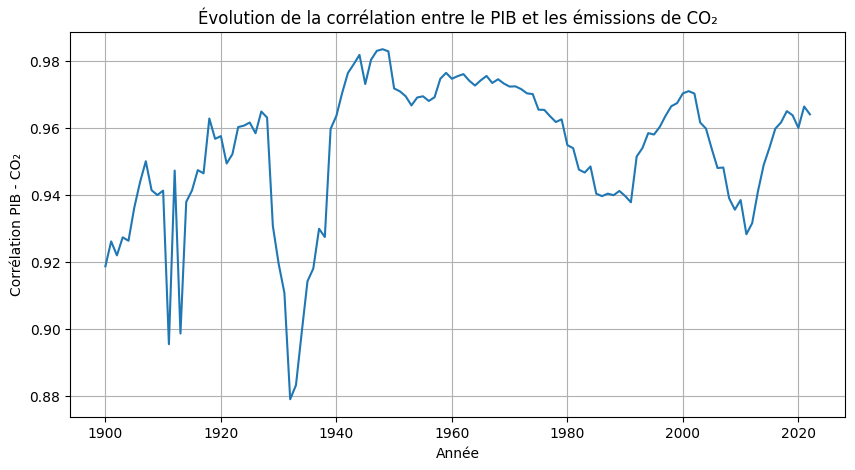

In [32]:
plt.figure(figsize=(10, 5))

plt.plot(corr_year.index, corr_year.values)

plt.xlabel("Année")
plt.ylabel("Corrélation PIB - CO₂")
plt.title("Évolution de la corrélation entre le PIB et les émissions de CO₂")

plt.grid()
plt.show()

In [33]:
corr_temporal = df.groupby("year").apply(
    lambda x: pd.Series({
        "PIB": x["co2"].corr(x["gdp"]),
        "Population": x["co2"].corr(x["population"])
    })
)

corr_temporal = corr_temporal.dropna()

print(corr_temporal.tail(10))

           PIB  Population
year                      
2013  0.941068    0.794124
2014  0.948991    0.798647
2015  0.954155    0.803767
2016  0.959800    0.809784
2017  0.961686    0.812519
2018  0.965071    0.814710
2019  0.963819    0.815553
2020  0.960056    0.813247
2021  0.966446    0.815755
2022  0.964109    0.817656


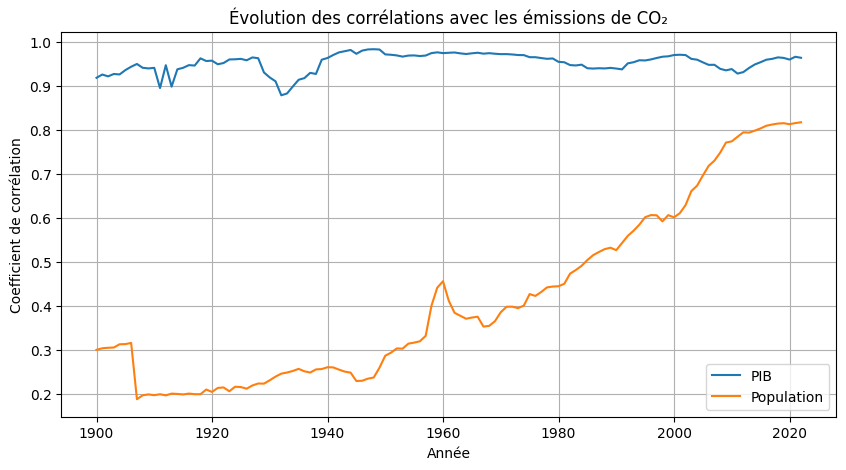

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(
    corr_temporal.index,
    corr_temporal["PIB"],
    label="PIB"
)

plt.plot(
    corr_temporal.index,
    corr_temporal["Population"],
    label="Population"
)

plt.xlabel("Année")
plt.ylabel("Coefficient de corrélation")
plt.title("Évolution des corrélations avec les émissions de CO₂")

plt.legend()
plt.grid()

plt.show()

In [35]:
df_pc = df[[
    "country",
    "year",
    "gdp",
    "population",
    "co2_per_capita"
]].dropna()

df_pc["gdp_per_capita"] = (
    df_pc["gdp"] / df_pc["population"]
)

corr_pc = df_pc["gdp_per_capita"].corr(
    df_pc["co2_per_capita"]
)

print("Corrélation PIB par habitant - CO₂ par habitant :", corr_pc)
print("Nombre d'observations :", len(df_pc))

Corrélation PIB par habitant - CO₂ par habitant : 0.5995352910862152
Nombre d'observations : 13382


In [36]:
corr_pc_year = df_pc.groupby("year").apply(
    lambda x: x["gdp_per_capita"].corr(
        x["co2_per_capita"]
    )
)

corr_pc_year = corr_pc_year.dropna()

print(corr_pc_year.tail(10))

year
2013    0.827637
2014    0.815100
2015    0.810111
2016    0.807287
2017    0.795045
2018    0.784566
2019    0.768635
2020    0.774508
2021    0.770137
2022    0.745470
dtype: float64


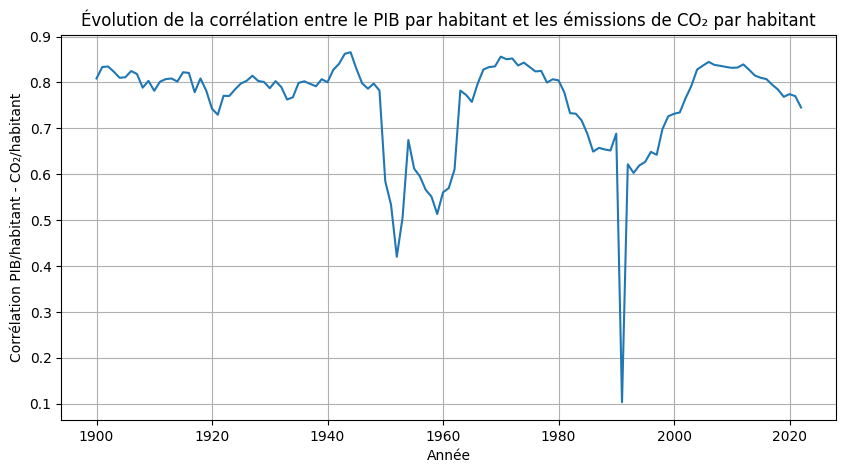

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(
    corr_pc_year.index,
    corr_pc_year.values
)

plt.xlabel("Année")
plt.ylabel("Corrélation PIB/habitant - CO₂/habitant")
plt.title(
    "Évolution de la corrélation entre le PIB par habitant "
    "et les émissions de CO₂ par habitant"
)

plt.grid()
plt.show()

In [38]:
df_analysis = df.copy()

def periode(year):
    if year <= 1949:
        return "1900-1949"
    elif year <= 1979:
        return "1950-1979"
    elif year <= 1999:
        return "1980-1999"
    elif year <= 2010:
        return "2000-2010"
    else:
        return "2011-2022"

df_analysis["periode"] = df_analysis["year"].apply(periode)

df_analysis["gdp_per_capita"] = (
    df_analysis["gdp"] / df_analysis["population"]
)

In [39]:
resultats = []

for periode, groupe in df_analysis.groupby("periode"):
    
    resultats.append({
        "Période": periode,
        "PIB-CO2": groupe["gdp"].corr(groupe["co2"]),
        "Population-CO2": groupe["population"].corr(groupe["co2"]),
        "PIB_hab-CO2_hab": groupe["gdp_per_capita"].corr(
            groupe["co2_per_capita"]
        )
    })

corr_periodes = pd.DataFrame(resultats)

print(corr_periodes)

     Période   PIB-CO2  Population-CO2  PIB_hab-CO2_hab
0  1900-1949  0.944857        0.231665         0.784505
1  1950-1979  0.966312        0.390438         0.728388
2  1980-1999  0.947687        0.546818         0.483382
3  2000-2010  0.951125        0.698797         0.795867
4  2011-2022  0.950446        0.808950         0.796171


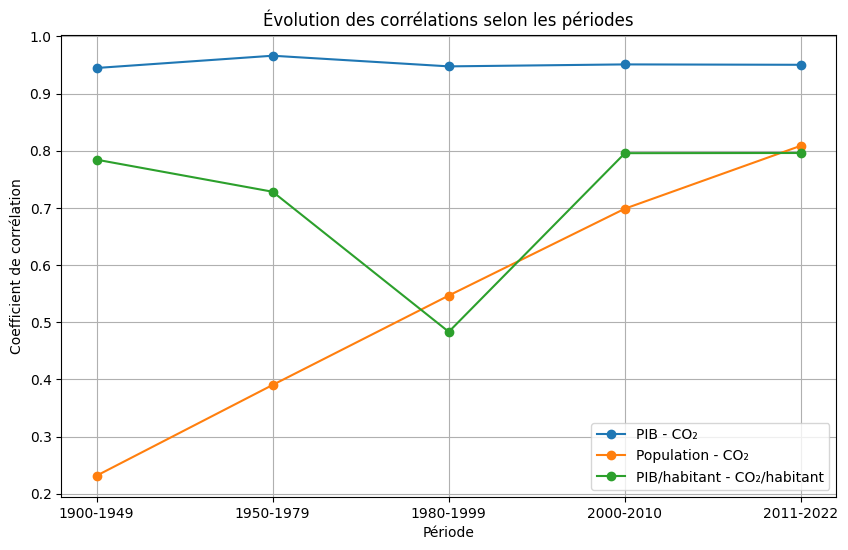

In [40]:
plt.figure(figsize=(10, 6))

plt.plot(
    corr_periodes["Période"],
    corr_periodes["PIB-CO2"],
    marker="o",
    label="PIB - CO₂"
)

plt.plot(
    corr_periodes["Période"],
    corr_periodes["Population-CO2"],
    marker="o",
    label="Population - CO₂"
)

plt.plot(
    corr_periodes["Période"],
    corr_periodes["PIB_hab-CO2_hab"],
    marker="o",
    label="PIB/habitant - CO₂/habitant"
)

plt.xlabel("Période")
plt.ylabel("Coefficient de corrélation")
plt.title("Évolution des corrélations selon les périodes")

plt.legend()
plt.grid()
plt.show()

In [44]:
df["gdp_per_capita"] = df["gdp"] / df["population"]

In [45]:
corr_vars = [
    "co2",
    "gdp",
    "population",
    "land_use_change_co2",
    "fossil_co2",
    "co2_per_capita",
    "gdp_per_capita",
    "temperature_change_from_ghg"
]

corr_matrix = df[corr_vars].corr()

print(corr_matrix.round(2))

                              co2   gdp  population  land_use_change_co2  \
co2                          1.00  0.93        0.63                 0.17   
gdp                          0.93  1.00        0.62                 0.15   
population                   0.63  0.62        1.00                 0.38   
land_use_change_co2          0.17  0.15        0.38                 1.00   
fossil_co2                   1.00  0.92        0.63                 0.18   
co2_per_capita               0.07  0.16       -0.01                -0.02   
gdp_per_capita               0.20  0.26       -0.01                -0.07   
temperature_change_from_ghg  0.88  0.87        0.55                 0.36   

                             fossil_co2  co2_per_capita  gdp_per_capita  \
co2                                1.00            0.07            0.20   
gdp                                0.92            0.16            0.26   
population                         0.63           -0.01           -0.01   
land_use_change

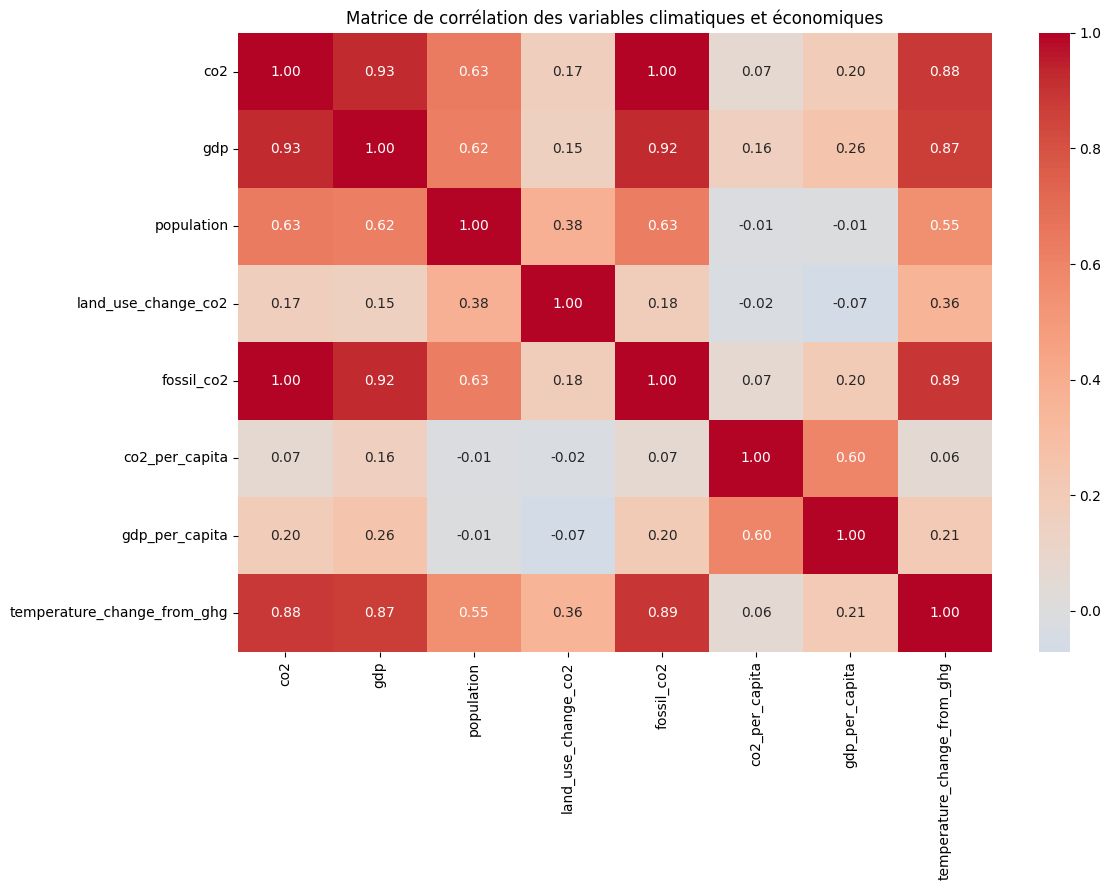

In [46]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matrice de corrélation des variables climatiques et économiques")
plt.tight_layout()
plt.show()

In [47]:
print(corr_matrix.round(2))

                              co2   gdp  population  land_use_change_co2  \
co2                          1.00  0.93        0.63                 0.17   
gdp                          0.93  1.00        0.62                 0.15   
population                   0.63  0.62        1.00                 0.38   
land_use_change_co2          0.17  0.15        0.38                 1.00   
fossil_co2                   1.00  0.92        0.63                 0.18   
co2_per_capita               0.07  0.16       -0.01                -0.02   
gdp_per_capita               0.20  0.26       -0.01                -0.07   
temperature_change_from_ghg  0.88  0.87        0.55                 0.36   

                             fossil_co2  co2_per_capita  gdp_per_capita  \
co2                                1.00            0.07            0.20   
gdp                                0.92            0.16            0.26   
population                         0.63           -0.01           -0.01   
land_use_change